# Campus DreamBooth and ControlNet

This is the author's training notebook, prepared for publication. Original training logs and image outputs are retained. Paths now use repository-relative data and configurable model directories. The saved outputs come from the original run, not a new run after these path changes.

The recorded run used 47 library photos for 30 epochs (1,410 updates). The notebook shows one generated image and one Canny conditioning image; its final ControlNet cell has no saved image output. See the separate project gallery for other exported project images.


In [1]:
import torch, torchvision, torchaudio
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())
print('torchaudio',torchaudio.__version__)

torch: 2.3.0
torchvision: 0.18.0
cuda available: True
torchaudio 2.3.0


In [2]:
!pip install -U diffusers transformers accelerate safetensors

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 21.2 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 61.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 791.7/791.7 kB 68.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 80.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 89.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 90.3 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [3]:
!pip install pandas

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 45.7 MB/s eta 0:00:00 0:00:01

[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [ ]:
from pathlib import Path
import os

CAMPUS_ROOT = Path.cwd().resolve()
if CAMPUS_ROOT.name == "notebooks":
    CAMPUS_ROOT = CAMPUS_ROOT.parent
BASE_MODEL_DIR = Path(os.environ.get("CAMPUS_BASE_MODEL_DIR", str(CAMPUS_ROOT / "models/base/sd_v1.5")))
CONTROLNET_MODEL_DIR = Path(os.environ.get("CAMPUS_CONTROLNET_MODEL_DIR", str(CAMPUS_ROOT / "models/base/sd-controlnet-canny")))
FINETUNED_MODEL_DIR = Path(os.environ.get("CAMPUS_FINETUNED_MODEL_DIR", str(CAMPUS_ROOT / "models/cuhksz_library_dreambooth")))
base_model_dir = str(BASE_MODEL_DIR)
instance_data_dir = str(CAMPUS_ROOT / "data/processed/library")
prompt_csv_path = str(CAMPUS_ROOT / "data/captions/library.csv")
print("Repository and model paths configured.")


In [5]:
import torch
import gc
import os

# 1. 清空PyTorch的GPU缓存（核心）
torch.cuda.empty_cache()

# 2. 强制垃圾回收（清理未引用的张量/模型）
gc.collect()

# 3. 可选：杀死可能占用显存的残留进程（丹摩平台专属，需谨慎）
# 仅当上述两步无效时用，会终止当前环境的其他Python进程
# os.system("nvidia-smi | grep python | awk '{print $3}' | xargs kill -9")

# 验证显存释放结果
def check_gpu_memory():
    if torch.cuda.is_available():
        allocated = torch.cuda.memory_allocated(0) / 1024**3  # 已分配显存（GB）
        cached = torch.cuda.memory_reserved(0) / 1024**3     # 缓存显存（GB）
        total = torch.cuda.get_device_properties(0).total_memory / 1024**3  # 总显存（GB）
        print(f"GPU总显存: {total:.2f}GB")
        print(f"已分配显存: {allocated:.2f}GB")
        print(f"缓存显存: {cached:.2f}GB")
        print(f"可用显存: {total - allocated:.2f}GB")
    else:
        print("CUDA不可用")

check_gpu_memory()

GPU总显存: 23.64GB
已分配显存: 0.00GB
缓存显存: 0.00GB
可用显存: 23.64GB


In [ ]:
import os
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch
from torchvision import transforms

class DreamBoothDataset(Dataset):
    def __init__(self, instance_data_dir, tokenizer, size=512, prompt_csv_path=None):
        self.size = size
        self.instance_data_dir = instance_data_dir
        self.tokenizer = tokenizer

        # 收集所有图片路径
        self.instance_images_path = [
            os.path.join(instance_data_dir, f)
            for f in os.listdir(instance_data_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]
        self.instance_images_path.sort()

        # 转换到 [-1, 1]
        self.transform = transforms.Compose([
            transforms.Resize((size, size), interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(size),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.prompt_dict = None
        if prompt_csv_path is not None:
            df = pd.read_csv(prompt_csv_path)
            self.prompt_dict = dict(zip(df["filename"], df["description"]))
    def __len__(self):
        return len(self.instance_images_path)

    def __getitem__(self, index):
        img_path = self.instance_images_path[index]
        img_name = os.path.basename(img_path)

        image = Image.open(img_path).convert("RGB")
        pixel_values = self.transform(image)

    # 找到对应caption
        if self.prompt_dict is not None:
            instance_prompt = self.prompt_dict.get(img_name)
            if instance_prompt is None:
                raise ValueError(f"CSV 里没有给 {img_name} 写 prompt")
        else:
            # 如果没传 CSV，就用统一触发词
            instance_prompt = "CUHK-Shenzhen library"
        input_ids = self.tokenizer(
            instance_prompt,
            truncation=True,
            max_length=self.tokenizer.model_max_length,
            return_tensors="pt"
        ).input_ids.squeeze(0)

        return {
            "pixel_values": pixel_values,
            "input_ids": input_ids,
        }

In [8]:
from diffusers import AutoencoderKL, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
import os
os.environ["HF_HUB_OFFLINE"] = "1" 
tokenizer = CLIPTokenizer.from_pretrained(str(BASE_MODEL_DIR / "tokenizer"),local_files_only=True)
text_encoder = CLIPTextModel.from_pretrained(
    str(BASE_MODEL_DIR / "text_encoder"),
    local_files_only=True,
).to(device)

vae = AutoencoderKL.from_pretrained(
    str(BASE_MODEL_DIR / "vae"),
    local_files_only=True,
).to(device)

unet = UNet2DConditionModel.from_pretrained(
    str(BASE_MODEL_DIR / "unet"),
    local_files_only=True,
).to(device)
print(text_encoder.dtype, unet.dtype, vae.dtype)
print("model transfer done!")

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
torch.float32 torch.float32 torch.float32
model transfer done!


In [9]:
train_dataset=DreamBoothDataset(
    instance_data_dir=instance_data_dir,
    tokenizer=tokenizer,
    size=512,
    prompt_csv_path=prompt_csv_path,
)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=1,   # 显存够可以改成 2 或 4
    shuffle=True,
)

print("训练样本数：", len(train_dataset))

训练样本数： 47


In [ ]:
from diffusers import DDPMScheduler
import torch.nn.functional as F

# 这是 SD1.5 常用的噪声调度参数
noise_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_start=0.00085,
    beta_end=0.012,
    beta_schedule="scaled_linear",
)

# 冻结 VAE，不训练
for p in vae.parameters():
    p.requires_grad_(False)

train_text_encoder = False
if not train_text_encoder:
    for p in text_encoder.parameters():
        p.requires_grad_(False)

# 只训练 UNet（以及可选text encoder）
params_to_optimize = list(unet.parameters())
if train_text_encoder:
    params_to_optimize += list(text_encoder.parameters())

optimizer = torch.optim.AdamW(
    params_to_optimize,
    lr=5e-6,
)

num_epochs = 30          # 先跑小一点测试流程
gradient_accumulation_steps = 1
print("OK")

OK


In [17]:
from tqdm.auto import tqdm
import torch.nn.functional as F
import torch

device = "cuda"

unet.train()
# 冻结 text_encoder（如果以后想一起训，就把这两行改成 text_encoder.train() + 去掉下面的 no_grad）
text_encoder.eval()
for p in text_encoder.parameters():
    p.requires_grad_(False)

torch.backends.cudnn.benchmark = True  # 对固定输入尺寸加速

scaler = torch.cuda.amp.GradScaler()   # 混合精度梯度缩放
global_step = 0

for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for batch in progress_bar:
        optimizer.zero_grad(set_to_none=True)

        # VAE 仍然不参与训练，no_grad 节省显存和算力
        with torch.no_grad():
            pixel_values = batch["pixel_values"].to(device, dtype=torch.float32)
            latents = vae.encode(pixel_values).latent_dist.sample()
            latents = latents * 0.18215

            noise = torch.randn_like(latents)
            bsz = latents.shape[0]
            timesteps = torch.randint(
                0, noise_scheduler.config.num_train_timesteps,
                (bsz,), device=device
            ).long()

            noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)
            input_ids = batch["input_ids"].to(device)

            # 文本编码器只做前向，不要梯度
            encoder_hidden_states = text_encoder(input_ids)[0]

        # 🔥 下面这块用混合精度
        with torch.cuda.amp.autocast(dtype=torch.float16):
            model_pred = unet(
                noisy_latents, timesteps, encoder_hidden_states
            ).sample

            target = noise
            loss = F.mse_loss(model_pred, target)

        # 使用 GradScaler 做反向和更新
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        global_step += 1
        progress_bar.set_postfix({"loss": float(loss.item()), "step": global_step})

print("训练完成 ✅")


Epoch 30/30: 100%|██████████| 47/47 [00:30<00:00,  1.52it/s, loss=0.00348, step=1410]

训练完成 ✅


In [18]:
from diffusers import StableDiffusionPipeline

save_dir = str(FINETUNED_MODEL_DIR)
print('start')
# 用原始 base_model_dir 加上你训练后的 unet（以及 text_encoder）
pipe = StableDiffusionPipeline.from_pretrained(
    base_model_dir,
    unet=unet,
    text_encoder=text_encoder,
    vae=vae,
    safety_checker=None,             # 👈 关键
    feature_extractor=None,          # 👈 关键
    torch_dtype=torch.float16,
    local_files_only=True,
).to(device)

pipe.save_pretrained(save_dir)
print("已保存到：", save_dir)


start


Loading pipeline components...: 100%|██████████| 5/5 [00:00<00:00, 21.83it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


已保存到： /root/shared-storage/cuhksz_library_dreambooth


Loading pipeline components...: 100%|██████████| 5/5 [00:23<00:00,  4.74s/it]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
100%|██████████| 30/30 [00:01<00:00, 26.77it/s]


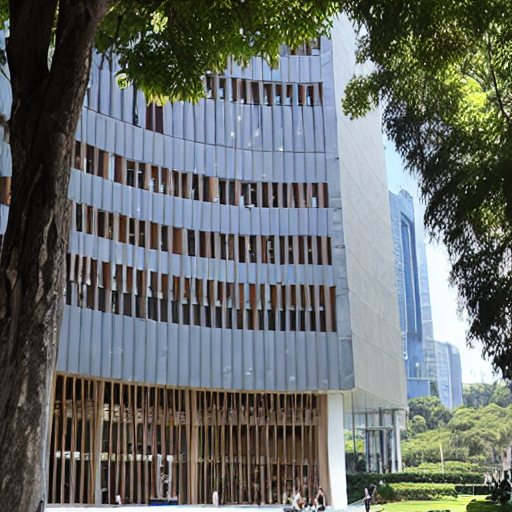

In [19]:
from diffusers import StableDiffusionPipeline
import torch

pipe = StableDiffusionPipeline.from_pretrained(
    str(FINETUNED_MODEL_DIR),
    torch_dtype=torch.float16,
    local_files_only=True,
).to("cuda")

prompt = "CUHK-Shenzhen library front in a sunny day"
with torch.autocast("cuda", dtype=torch.float16):
    image = pipe(prompt, num_inference_steps=30, guidance_scale=7.5).images[0]

image

In [23]:
from diffusers import ControlNetModel
from diffusers import StableDiffusionControlNetPipeline

controlnet = ControlNetModel.from_pretrained(
    str(CONTROLNET_MODEL_DIR),
    torch_dtype=torch.float16,
    local_files_only=True
).to("cuda")

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    str(FINETUNED_MODEL_DIR),   # 你的 DreamBooth 模型目录
    controlnet=controlnet,
    safety_checker=None,
    feature_extractor=None,
    torch_dtype=torch.float16,
).to(device)

# pipe.enable_xformers_memory_efficient_attention()

Loading pipeline components...: 100%|██████████| 5/5 [00:22<00:00,  4.54s/it]
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


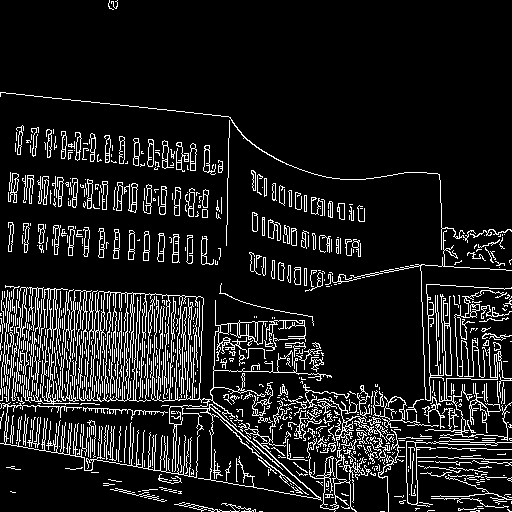

In [29]:
from PIL import Image
import numpy as np
import cv2

def make_canny_image(path, size=512):
    img = Image.open(path).convert("RGB")
    img = img.resize((size, size))
    np_img = np.array(img)

    edges = cv2.Canny(np_img, 100, 200)
    edges = np.stack([edges] * 3, axis=-1)  # 单通道 → 3 通道
    canny_image = Image.fromarray(edges)
    return canny_image

canny_image = make_canny_image(str(CAMPUS_ROOT / "data/processed/library/Library44.jpg"))
canny_image

In [ ]:
prompt = "a photo of CUHK-Shenzhen library. It's raining and thundering. The rain is very big"

with torch.autocast("cuda", dtype=torch.float16):
    out = pipe(
        prompt=prompt,
        image=canny_image,                      # ControlNet 条件图
        num_inference_steps=150,
        guidance_scale=7.5,                     # 文本引导强度
        controlnet_conditioning_scale=1.0,      # ControlNet 约束强度 (0~2)
    )

result = out.images[0]
result

 74%|███████▍  | 111/150 [00:05<00:02, 18.97it/s]